# code_033 · Leakage and information boundaries

**Book:** section 7.2. These are synthetic mechanism experiments, not observed structural performance, safety assessment, a causal study or an estimator leaderboard. Each experiment states which cases are unseen and which outcomes are available. Fits and preprocessing use training observations only. Development curves support diagnosis; final outcomes are opened only after the stated rule is fixed. Constructed identities and stress cases are not held-out population estimates.

Restart and run all cells. All imports, helpers and data generation are here; no ordinary-run files, network, API key, GPU or private module is required. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [traceability guide](../CHAPTER_07_GUIDE.md), [execution evidence](../CHAPTER_07_EXECUTION.md) and [permanent registry](../CODE_EXAMPLES.md#code_033). Reference environment: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute for execution and 30–60 minutes for interpretation. These scoped labs disclose relevant controls rather than cover every constructor parameter.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=733;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 733


<a id="join"></a>
## Rebuild the feature path, not just the final column list

Thirty buildings each supply eight monthly prediction cases. Target y=.3+1.2*load+.6*building_offset+noise sd .08 mm. Buildings 0–17/18–23/24–29 form training/development/final groups (144/48/48 cases). New-building prediction is the declared task. Training, development and final cutoffs occur in 2024, 2025 and 2026 respectively; source labels and development selection are available before each later assessment period.

For each case, a source table contains three sensor/report records: an available pre-prediction measurement (event -2 days, arrival -1), a late-arriving old record (event -3, arrival +2), and a post-inspection measurement (event +2, arrival +3). The available prior measurement is a noisy response proxy; the post-inspection value almost copies the target. Eligibility requires both event and arrival no later than cutoff. A naïve relational merge also triples rows. Select the latest eligible event per case, then enforce one-to-one case joins.


In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
G=30;m=8;N=G*m;building=np.repeat(np.arange(G),m);load=rng.uniform(0,1,N);offset=rng.normal(0,.7,G)
y=.3+1.2*load+.6*offset[building]+rng.normal(0,.08,N)
cutoff=np.concatenate([pd.date_range(f'{2024+int(g>=18)+int(g>=24)}-01-01',periods=m,freq='MS').to_numpy() for g in range(G)])
cases=pd.DataFrame({'case_id':np.arange(N),'building':building,'cutoff':cutoff,'load':load})
prior=.3+1.2*load+.6*offset[building]+rng.normal(0,.18,N);post=y+rng.normal(0,.001,N)
records=[]
for i in range(N):
 for event,arrival,value,kind in [(-2,-1,prior[i],'available'),(-3,2,y[i],'late_old'),(2,3,post[i],'post_inspection')]:
  records.append([i,cutoff[i]+pd.Timedelta(days=event),cutoff[i]+pd.Timedelta(days=arrival),value,kind])
observations=pd.DataFrame(records,columns=['case_id','event_time','arrival_time','value','kind'])
expanded=cases.merge(observations,on='case_id');assert len(expanded)==3*N
cardinality_rejected=False
try:cases.merge(observations,on='case_id',validate='one_to_one')
except pd.errors.MergeError:cardinality_rejected=True
assert cardinality_rejected
eligible=expanded[(expanded.event_time<=expanded.cutoff)&(expanded.arrival_time<=expanded.cutoff)]
latest=eligible.sort_values('event_time').drop_duplicates('case_id',keep='last')[['case_id','value','kind']]
clean=cases.merge(latest,on='case_id',validate='one_to_one').sort_values('case_id')
assert len(clean)==N and set(clean.kind)=={'available'} and clean.case_id.is_unique
assert 'late_old' not in set(clean.kind) and 'post_inspection' not in set(clean.kind)
RESULTS['raw_join_rows']=len(expanded);RESULTS['repaired_rows']=len(clean)


<a id="audit"></a>
## Three other leakage paths

For a new-building claim, a split by early/late reading index across all buildings fails group separation; removing the ID does not remove shared offsets. A target-derived building mean computed over all cases changes when an assessment outcome changes, so it is not an available feature. Fitting a scaler on all input cases also violates this notebook's inductive boundary even without labels; it need not improve a score to be invalid. The repair fits all preprocessing again on training only after reconstructing eligible features.


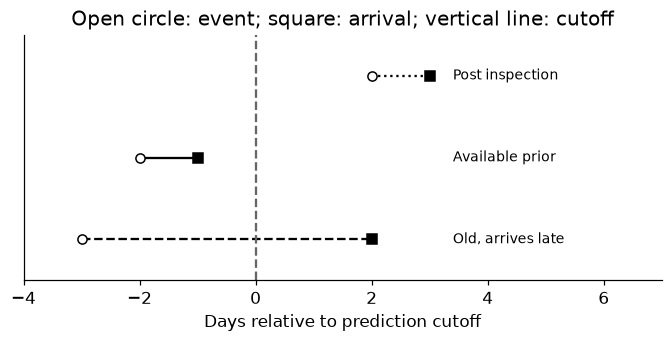

In [3]:
tr=np.flatnonzero(building<18);dv=np.flatnonzero((building>=18)&(building<24));te=np.flatnonzero(building>=24)
assert not set(building[tr])&set(building[dv]) and not set(building[tr])&set(building[te])
assert cases.cutoff.iloc[tr].max()+pd.Timedelta(days=3)<cases.cutoff.iloc[dv].min()
assert cases.cutoff.iloc[dv].max()+pd.Timedelta(days=3)<cases.cutoff.iloc[te].min()
reading=np.tile(np.arange(m),G);bad_train=reading<4;bad_eval=reading>=4;overlap=set(building[bad_train])&set(building[bad_eval]);assert len(overlap)==G
bad_aggregate=pd.Series(y).groupby(building).transform('mean').to_numpy();changed=y.copy();changed[dv[0]]+=8
changed_aggregate=pd.Series(changed).groupby(building).transform('mean').to_numpy()
assert np.isclose(changed_aggregate[dv[0]]-bad_aggregate[dv[0]],1.)
X=np.column_stack([load,clean.value.to_numpy()]);clean_saved=X.copy()
assert np.array_equal(X,clean_saved) and not np.array_equal(bad_aggregate,changed_aggregate)
train_scaler=StandardScaler().fit(X[tr]);all_scaler=StandardScaler().fit(X)
assert np.allclose(train_scaler.mean_,X[tr].mean(0)) and not np.allclose(train_scaler.mean_,all_scaler.mean_)
RESULTS['invalid_split_overlapping_buildings']=len(overlap);RESULTS['aggregate_assessment_label_sensitivity']=1.
fig,ax=plt.subplots(figsize=(6,3));events=[(-3,2,'Old, arrives late'),(-2,-1,'Available prior'),(2,3,'Post inspection')]
for j,(event,arrival,label) in enumerate(events):ax.plot([event,arrival],[j,j],color='black',ls=['--','-',':'][j]);ax.plot(event,j,'ko',mfc='white');ax.plot(arrival,j,'ks');ax.text(3.4,j,label,va='center',fontsize=9)
ax.axvline(0,color='.4',ls='--');ax.set(xlim=(-4,7),ylim=(-.5,2.5),yticks=[],xlabel='Days relative to prediction cutoff',title='Open circle: event; square: arrival; vertical line: cutoff');plt.show()


<a id="development"></a>
## A suspiciously strong score can answer an invalid question

Compare two fixed alpha=1 ridge pipelines on development cases: the repaired load/prior-measurement inputs and an invalid load/post-inspection input set. Both scale using training rows, so the invalid improvement comes from the unavailable target-like field, not a different scaler boundary. This leaky model is a diagnostic counterexample, never an eligible model selected for final deployment.


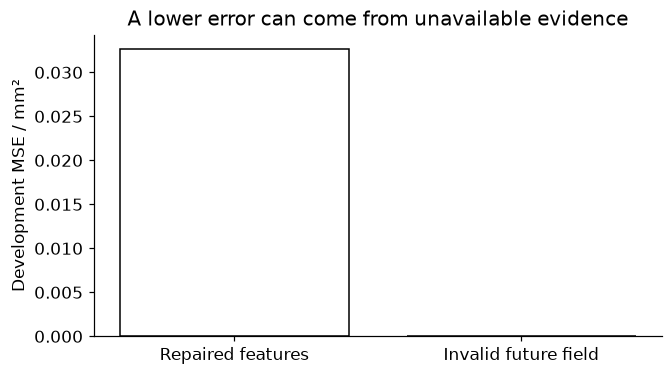

In [4]:
leaky_X=np.column_stack([load,post]);model=make_pipeline(StandardScaler(),Ridge(alpha=1.)).fit(X[tr],y[tr]);leaky=make_pipeline(StandardScaler(),Ridge(alpha=1.)).fit(leaky_X[tr],y[tr])
errors={'repaired':float(np.mean((model.predict(X[dv])-y[dv])**2)),'invalid_post_inspection':float(np.mean((leaky.predict(leaky_X[dv])-y[dv])**2))}
assert np.allclose(model[0].mean_,X[tr].mean(0)) and errors['invalid_post_inspection']<errors['repaired']
fig,ax=plt.subplots(figsize=(6,3.3));ax.bar(['Repaired features','Invalid future field'],list(errors.values()),color=['white','.6'],edgecolor='black');ax.set(ylabel='Development MSE / mm²',title='A lower error can come from unavailable evidence');plt.show()
RESULTS['development_MSE_mm2']=errors


<a id="final"></a>
## Final evidence uses only the repaired path

The original clean rule and metric are fixed. Final cases are from six buildings not present in training/development. Prediction inputs were reconstructed without target-derived aggregates or post-cutoff records. The invalid model is not scored again as a competing final candidate. Later revisions need fresh final buildings.


In [5]:
pred=model.predict(X[te]);mae=float(np.mean(abs(pred-y[te])))
assert pred.shape==(48,) and np.isfinite(mae) and len(np.unique(building[te]))==6
assert not set(building[dv])&set(building[te])
RESULTS['repaired_final_MAE_mm']=mae;RESULTS['final_independent_buildings']=6;print(RESULTS)


{'raw_join_rows': 720, 'repaired_rows': 240, 'invalid_split_overlapping_buildings': 30, 'aggregate_assessment_label_sensitivity': 1.0, 'development_MSE_mm2': {'repaired': 0.03264794932026516, 'invalid_post_inspection': 2.6099953501522833e-05}, 'repaired_final_MAE_mm': 0.1534105273827817, 'final_independent_buildings': 6}


<a id="exercises"></a>
## Exercises and hints

1. Make an early-event record arrive after prediction. Explain why event-time-only filtering fails.
2. Add multiple inspections per member. Check join multiplicity before splitting or computing weights.
3. Rebuild a target encoding within training folds; handle unseen buildings without using their outcomes.
4. Specify a known-building future-reading contract for which a temporal split is useful; compare it with the new-building contract here.

**Hints:** leakage is a violation of the declared information contract, not just a suspicious column name. Repair joins, aggregates, fitted preprocessing and model selection together. See official [common pitfalls](https://scikit-learn.org/1.9/common_pitfalls.html) and [join cardinality](https://pandas.pydata.org/docs/user_guide/merging.html) documentation. As-of tools require explicit keys, sorting and availability semantics; a backward event match alone does not establish arrival eligibility.


In [6]:
summary={'example_id':'code_033','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['target temporal group relational and preprocessing leakage', 'event time versus arrival time', 'as-of eligible join and cardinality repair', 'outcome-derived aggregate sensitivity', 'clean refit and protected new-building assessment'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["target temporal group relational and preprocessing leakage", "event time versus arrival time", "as-of eligible join and cardinality repair", "outcome-derived aggregate sensitivity", "clean refit and protected new-building assessment"], "elapsed_seconds": 0.195, "example_id": "code_033", "hardware": "Darwin arm64 CPU", "results": {"aggregate_assessment_label_sensitivity": 1.0, "development_MSE_mm2": {"invalid_post_inspection": 2.6099953501522833e-05, "repaired": 0.03264794932026516}, "final_independent_buildings": 6, "invalid_split_overlapping_buildings": 30, "raw_join_rows": 720, "repaired_final_MAE_mm": 0.1534105273827817, "repaired_rows": 240}, "seed": 733, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
